# 04 - Data Integration (BijliCast)

**CT-378 Phase 2 - integration step**

Merges the three inputs into one modelling table:
1. Household electricity (hourly mean kW)
2. Open-Meteo ERA5 weather (hourly, 8 usable variables)
3. `metadata_ultimate.xlsx` static household features

Output: `data/processed/merged_dataset.parquet`.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)

Repo root: D:\BijliCast


## 1. Load the hourly electricity + weather table

In [2]:
df = pd.read_parquet(PROC / "hourly_combined.parquet")
df["datetime"] = pd.to_datetime(df["datetime"])
print("hourly_combined:", df.shape)
print("houses:", df["house_id"].nunique(), "| cities:", df["city"].nunique())
df.head(3)

hourly_combined:

 (515786, 12)
houses: 59 | cities: 6


,datetime,usage_kw,house_id,city,temperature,humidity,dew,precipitation,wind_speed,wind_direction,pressure,solar_radiation
0,2023-11-01 00:00:00,0.525333,House#41,Islamabad,17.9,75,13.5,0.0,5.2,344,957.3,0.0
1,2023-11-01 01:00:00,0.560500,House#41,Islamabad,18.2,72,13.2,0.0,6.2,339,957.3,0.0
2,2023-11-01 02:00:00,0.593833,House#41,Islamabad,18.6,70,13.1,0.0,5.0,330,957.3,0.0


## 2. Load and clean household metadata

In [3]:
meta = pd.read_excel(ROOT / "datasets" / "metadata_ultimate.xlsx")
# Normalise column names: remove newlines and trailing spaces
meta.columns = [str(c).replace("\n", " ").strip() for c in meta.columns]
meta = meta.rename(columns={"House": "house_id", "City": "city"})
print("metadata:", meta.shape)
print("sample columns:", list(meta.columns)[:8])

metadata: (59, 46)
sample columns: ['house_id', 'city', 'Owner/Rented', 'No. of people (Temp+Perm)', 'No. of Permanent residents', 'No. of Children (0-13)', 'No. of Adults (14-60)', 'No. of Seniors (above 60)']


## 3. Verify the join key covers all 59 houses

In [4]:
# metadata uses house_id like 'House#1'; our table uses the same convention
merged_keys = set(zip(df["house_id"], df["city"]))
meta_keys = set(zip(meta["house_id"], meta["city"]))
print("houses in tables :", len(merged_keys))
print("houses in metadata:", len(meta_keys))
print("missing from metadata:", merged_keys - meta_keys)
print("extra in metadata   :", meta_keys - merged_keys)

houses in tables : 59
houses in metadata: 59
missing from metadata: set()
extra in metadata   : set()


## 4. Select curated static household features and merge

In [5]:
static_cols = [
    "house_id", "city",
    "No. of people (Temp+Perm)", "No. of Adults (14-60)", "No. of Children (0-13)",
    "Property Area (Marla)", "Covered Area", "No of Floors", "No. of rooms",
    "Air Conditioners", "Air Coolers", "Refrigerators", "Washing Machines",
    "Celling Fans", "Wall Fans", "Water Pumps", "Geysers", "Electric heaters",
    "UPS", "Build year of house", "Owner/Rented",
]
static_cols = [c for c in static_cols if c in meta.columns]
static = meta[static_cols].copy()
merged = df.merge(static, on=["house_id", "city"], how="left")

print("Merged shape:", merged.shape)
print("Columns:", len(merged.columns))
print("Static columns added:", [c for c in static_cols if c not in ("house_id", "city")])
merged.head(3)

Merged shape: (515786, 31)
Columns: 31
Static columns added: ['No. of people (Temp+Perm)', 'No. of Adults (14-60)', 'No. of Children (0-13)', 'Property Area (Marla)', 'Covered Area', 'No of Floors', 'No. of rooms', 'Air Conditioners', 'Air Coolers', 'Refrigerators', 'Washing Machines', 'Celling Fans', 'Wall Fans', 'Water Pumps', 'Geysers', 'Electric heaters', 'UPS', 'Build year of house', 'Owner/Rented']


,datetime,usage_kw,house_id,city,temperature,humidity,dew,precipitation,wind_speed,wind_direction,...,Refrigerators,Washing Machines,Celling Fans,Wall Fans,Water Pumps,Geysers,Electric heaters,UPS,Build year of house,Owner/Rented
0,2023-11-01 00:00:00,0.525333,House#41,Islamabad,17.9,75,13.5,0.0,5.2,344,...,1.0,1,5.0,2.0,1.0,0.0,0.0,0.0,2014.0,Owner
1,2023-11-01 01:00:00,0.560500,House#41,Islamabad,18.2,72,13.2,0.0,6.2,339,...,1.0,1,5.0,2.0,1.0,0.0,0.0,0.0,2014.0,Owner
2,2023-11-01 02:00:00,0.593833,House#41,Islamabad,18.6,70,13.1,0.0,5.0,330,...,1.0,1,5.0,2.0,1.0,0.0,0.0,0.0,2014.0,Owner


## 5. Integration quality check

In [6]:
print("Rows:", f"{len(merged):,}")
print("Houses:", merged["house_id"].nunique())
print()
print("Missing % (top 15):")
print((merged.isna().mean() * 100).round(2).sort_values(ascending=False).head(15).to_string())
print()
print("CT-378 >= 5,000 rows:", "PASS" if len(merged) >= 5000 else "FAIL")
print("Feature columns (excl. datetime/house_id/city/target):",
      len([c for c in merged.columns if c not in ("datetime", "house_id", "city", "usage_kw")]))

Rows: 515,786
Houses: 59

Missing % (top 15):
usage_kw                     2.52
No. of Children (0-13)       1.70
No. of Adults (14-60)        1.70
No. of people (Temp+Perm)    1.70
Build year of house          1.70
UPS                          1.70
Electric heaters             1.70
Celling Fans                 1.70
Wall Fans                    1.70
Water Pumps                  1.70
Refrigerators                1.70
Air Conditioners             1.70
No. of rooms                 1.70
Covered Area                 1.70
Property Area (Marla)        1.70

CT-378 >= 5,000 rows: PASS
Feature columns (excl. datetime/house_id/city/target): 27


### Plot 11 - Coverage after integration (hourly rows per house)

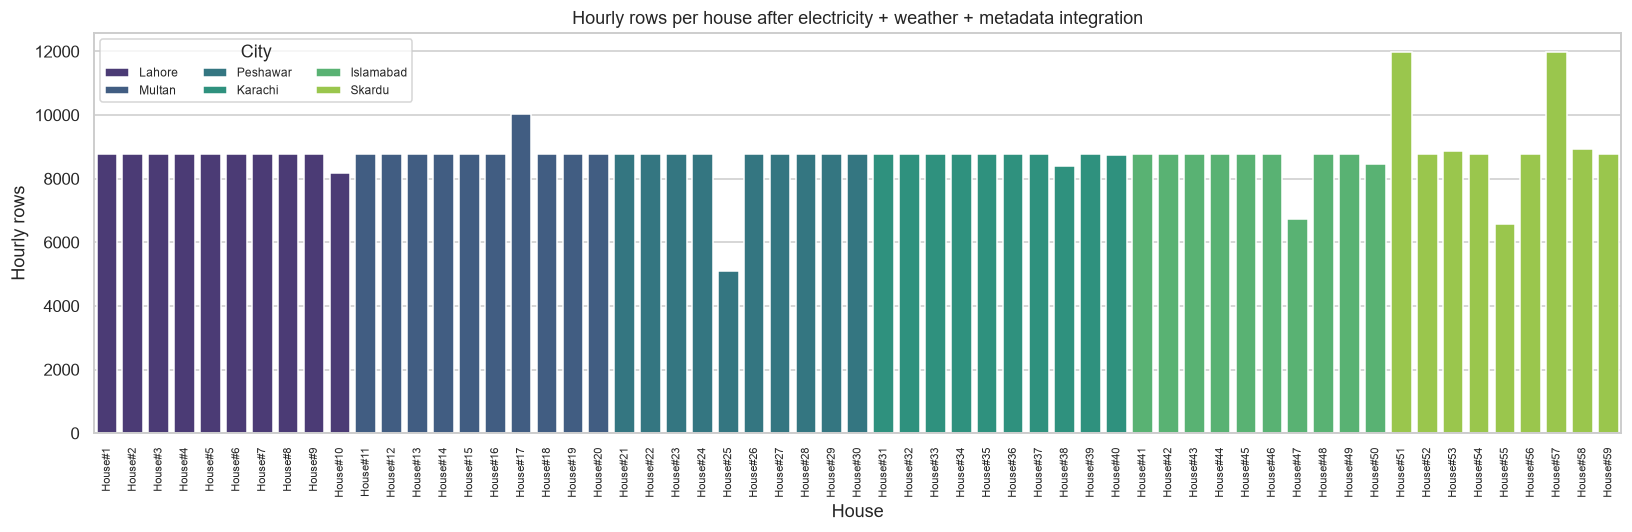

In [7]:
rows = merged.groupby(["city", "house_id"]).size().reset_index(name="rows")
rows["house_num"] = rows["house_id"].str.extract(r"(\d+)").astype(int)
rows = rows.sort_values("house_num")
plt.figure(figsize=(15, 5))
sns.barplot(data=rows, x="house_id", y="rows", hue="city", dodge=False, palette="viridis")
plt.title("Hourly rows per house after electricity + weather + metadata integration")
plt.xlabel("House")
plt.ylabel("Hourly rows")
plt.xticks(rotation=90, fontsize=7)
plt.legend(title="City", ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "04_integration_rows_per_house.png", dpi=220, bbox_inches="tight")
plt.show()

## 6. Save the integrated modelling table

In [8]:
out = PROC / "merged_dataset.parquet"
merged.to_parquet(out, index=False)
print("Saved ->", out, f"({out.stat().st_size/1024/1024:.1f} MB)")
print("Shape:", merged.shape)

Saved -> D:\BijliCast\data\processed\merged_dataset.parquet (8.3 MB)
Shape: (515786, 31)


## Findings - Notebook 04

- All **59 houses** join cleanly to `metadata_ultimate.xlsx` (no missing keys).
- The integrated table combines **electricity + weather + 19 static household features**.
- Weather coverage is now complete (extended Open-Meteo range); only genuine `usage_kw` meter gaps remain.
- Output saved to `data/processed/merged_dataset.parquet` for feature engineering (Phase 3).